## Time Series Grid SANOS Market Generation Test, AC 10

This notebook computes historic time series for implied vols, fitting error, DLV vs a gixed NMS grid.



In [1]:

import os
os.environ["JAX_ENABLE_X64"] = "True"

%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.arbfree
%aimport quantdata.widb.options_filter
%aimport quantdata.widb.timeseries
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.sanos.sanos_tools
%aimport quantdata.sanos.arbfree
%aimport quantdata.sanos.sanos
%aimport quantdata.dysanos.grid.interpolated
%aimport quantdata.dysanos.grid.torch_load
%aimport quantdata.dysanos.grid.torch_model
%aimport quantdata.dysanos.grid.torch_gfx 
%aimport quantdata.dysanos.grid.torch_train 

from quantdata.dysanos.grid.torch_load import load, date
r_nms = load("nms", start=date(2020,1,1))
print(f"nms /done - found {len(r_nms.ts['dates'])} dates.")
    

nms /done - found 1412 dates.


00: Training long_state version 0.1 { preprocess: 0.1 { load: 0.1 { ExpiryFilter: 0.5, GridConfig: 0.1, MkArbFree: 0.51 { ArbFreePricer: 0.8 }, OptionsFilter: 0.62, RawDayFilter: 0.5, interpolate_time_series: 0.16 { interpolate_grid: 0.14 { ExpiryFilter: 0.5, GridConfig: 0.1, MkArbFree: 0.51 { ArbFreePricer: 0.8 }, OptionsFilter: 0.62, RawDayFilter: 0.5, SanosFitter: 0.4 { SanosPricer: 0.8 }, filter_options_day: 0.2 { OptionsFilter: 0.62, enrich_day: 0.8 { ExpiryFilter: 0.5, collect_raw_day: 0.7 { WIDBClient: 1.0 { WRDSCredentials: 0.1 }, interpolate_zero_curve: 0.1 } }, mk_arb_free_day: 0.6 { MkArbFree: 0.51 { ArbFreePricer: 0.8 }, enrich_day: 0.8 { ExpiryFilter: 0.5, collect_raw_day: 0.7 { WIDBClient: 1.0 { WRDSCredentials: 0.1 }, interpolate_zero_curve: 0.1 } } }, normalize_day: 0.3 { enrich_day: 0.8 { ExpiryFilter: 0.5, collect_raw_day: 0.7 { WIDBClient: 1.0 { WRDSCredentials: 0.1 }, interpolate_zero_curve: 0.1 } } } } } } } } } for 200000 epochs on SPX for date range 2020-01-01_20

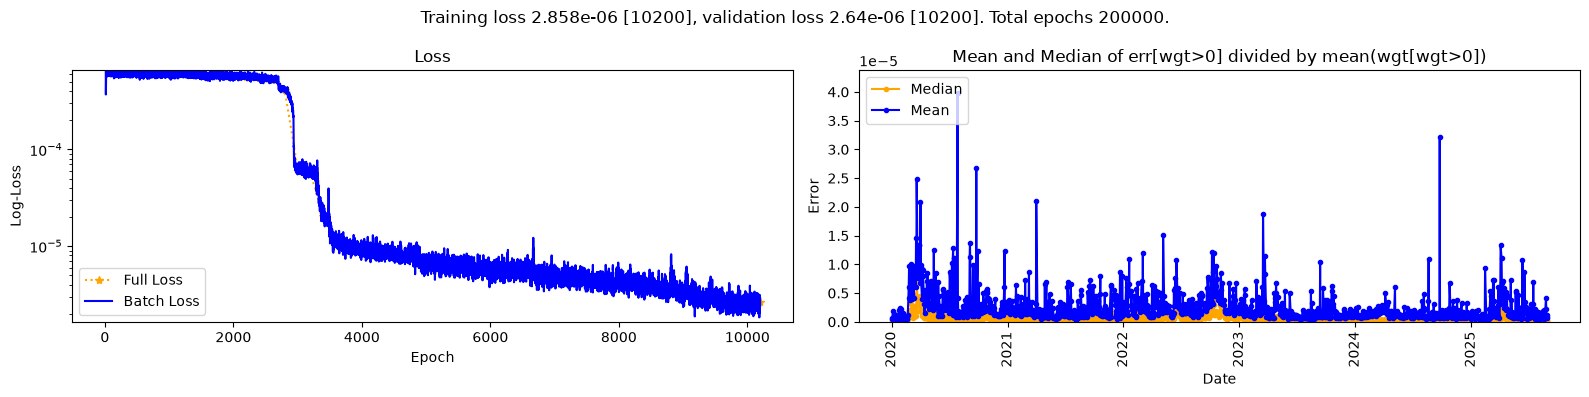

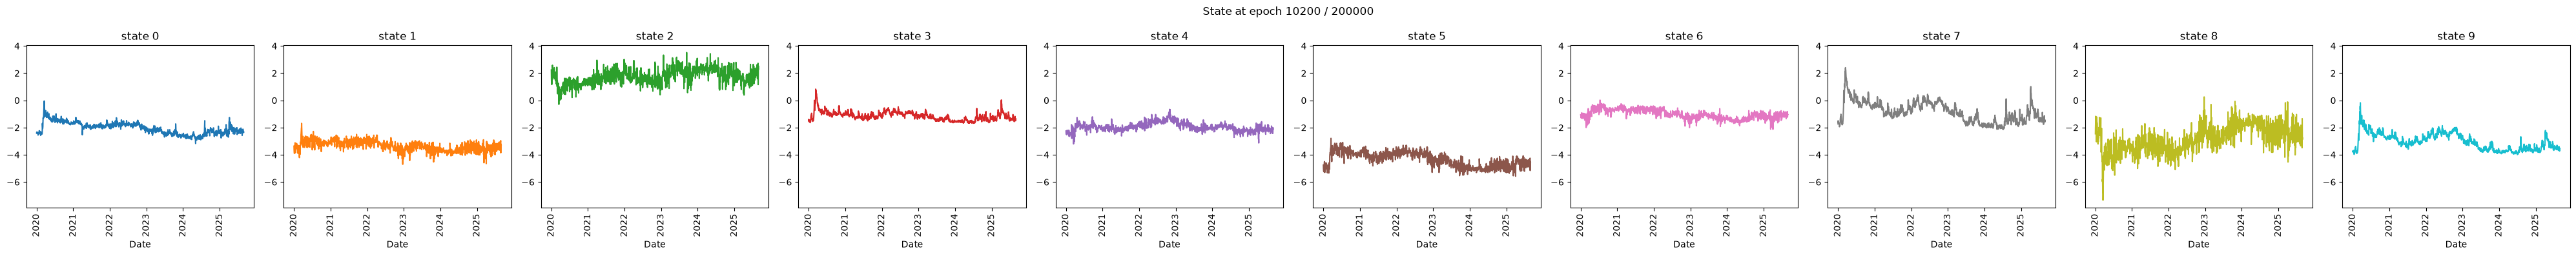

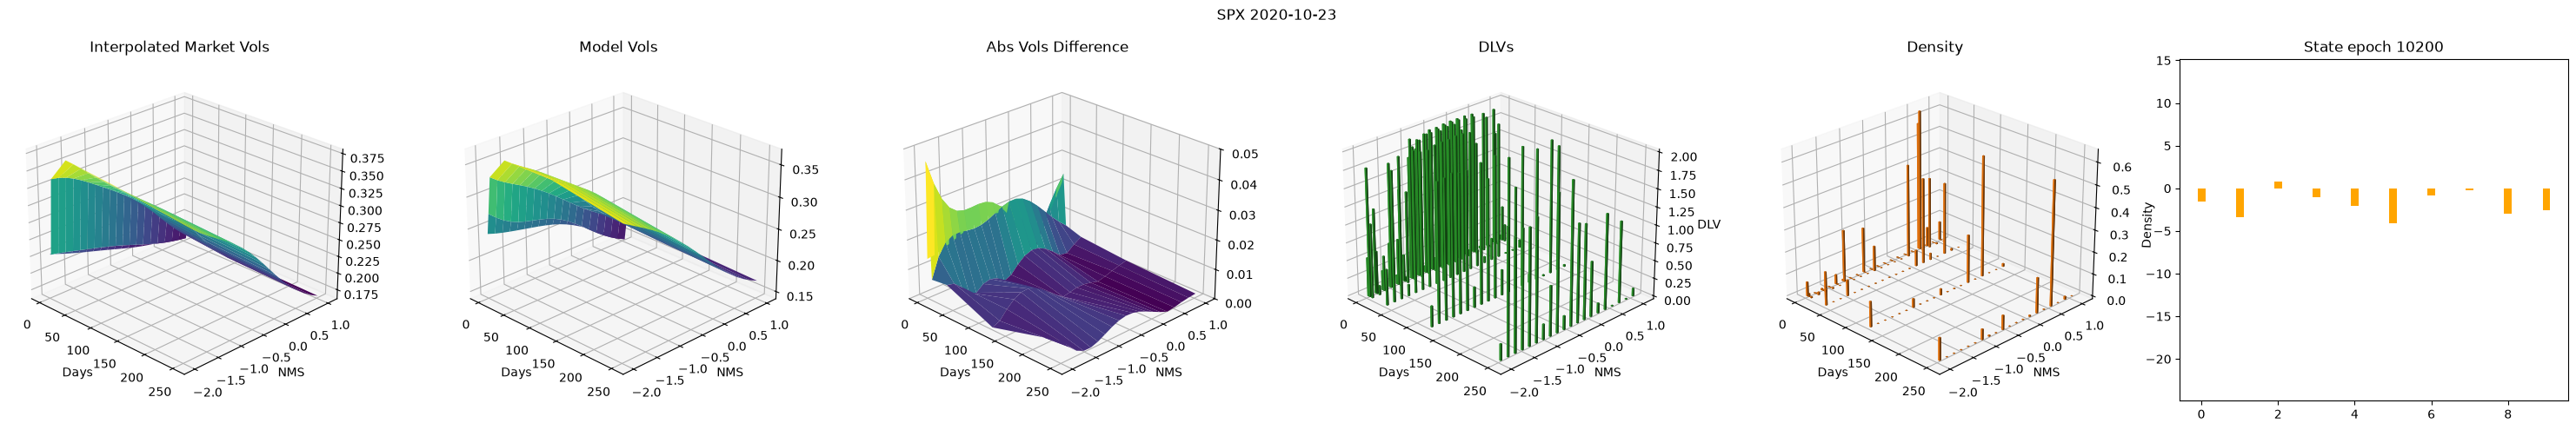

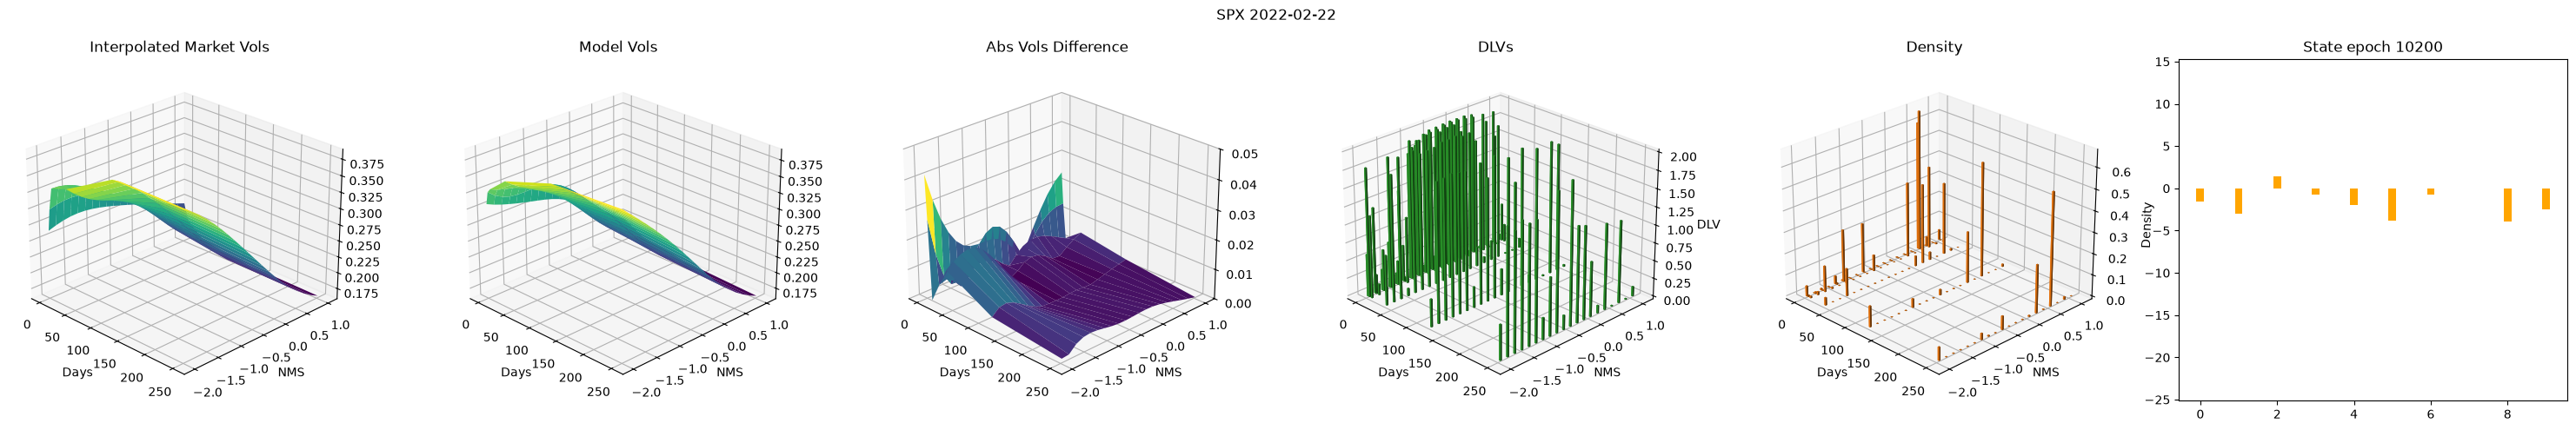

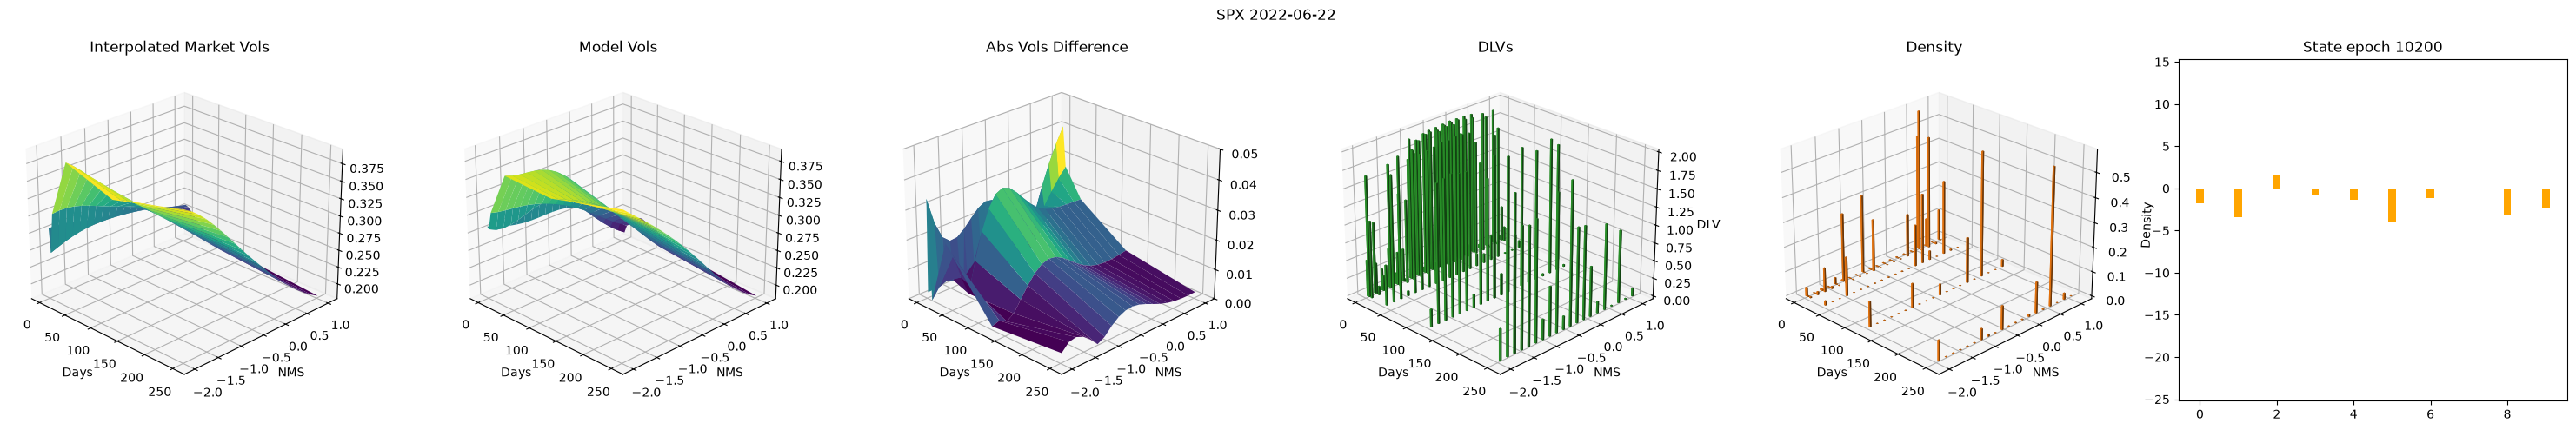

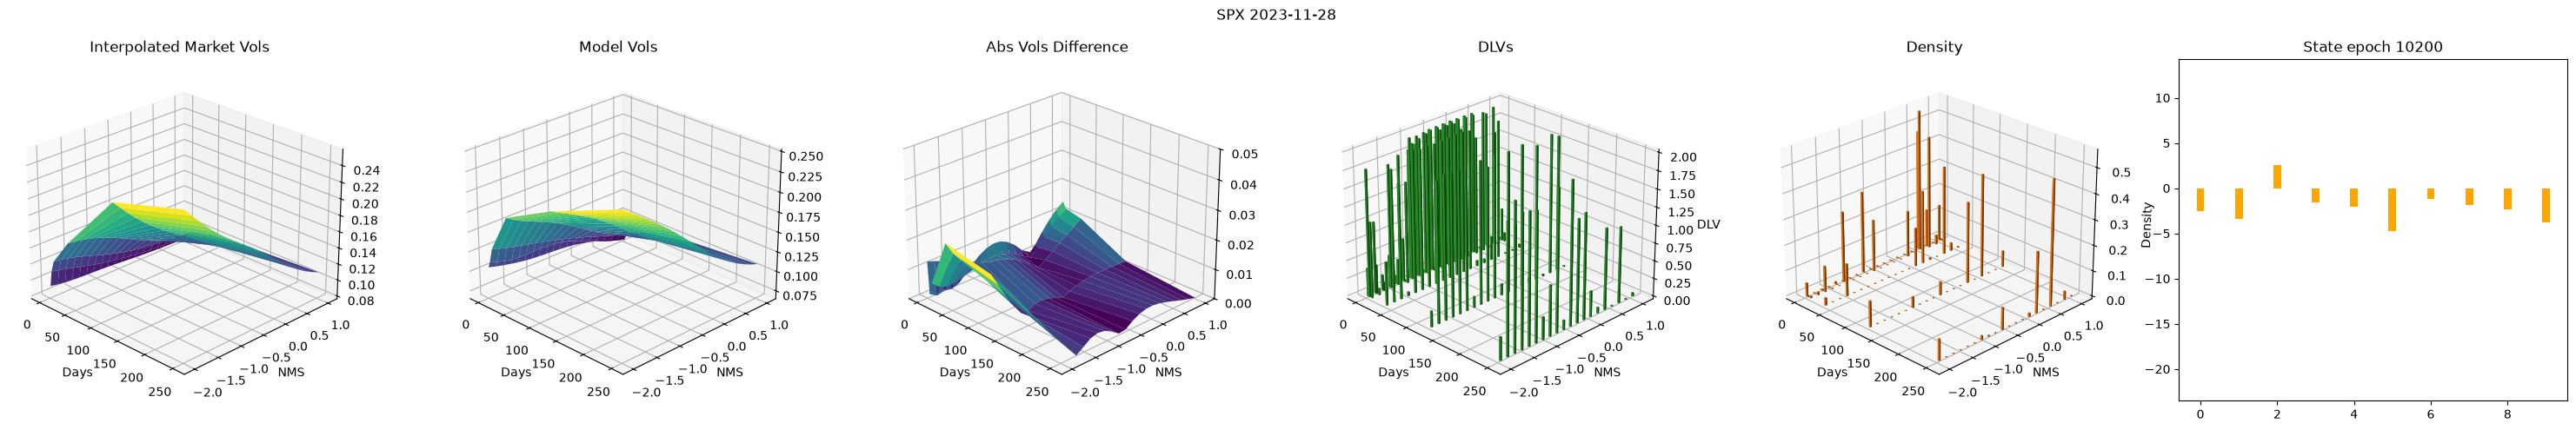

00: Training 0.25-smooth@10 midlv=0.01,mxdlv=2.00,vsq=0.0001 st=FF(d=2,w=100,a=SELU,b=True),lrn=FF(d=2,w=100,a=SELU,b=True) with TrainConfig(num_epochs=200000, lr=0.001, weight_decay=0.01, batch_size=128) on Env(prec=32,device=cpu,debug=False):
01:   Epoch 1/200000, Loss: 0.06502. So far this took 0.059s.

/home/hans/vqdata/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations


01:   Epoch 1/200000, Loss: 0.06502. Valuation loss: 0.06336. So far this took 1.7s. [Check point saved]
01:   Epoch 200/200000, Loss: 0.0005986. Valuation loss: 0.0006134. So far this took 6s. [Check point saved]
01:   Epoch 400/200000, Loss: 0.0005894. Valuation loss: 0.0006032. So far this took 11s. [Check point saved]
01:   Epoch 600/200000, Loss: 0.0005673. Valuation loss: 0.000603. So far this took 18s. [Check point saved]
01:   Epoch 800/200000, Loss: 0.0005901. Valuation loss: 0.0005989. So far this took 23s. [Check point saved]
01:   Epoch 1000/200000, Loss: 0.0005831. Valuation loss: 0.0005989. So far this took 29s. [Check point saved]
01:   Epoch 1200/200000, Loss: 0.0006357. Valuation loss: 0.0005989. So far this took 34s. [Check point saved]
01:   Epoch 1400/200000, Loss: 0.0006092. Valuation loss: 0.0005893. So far this took 40s. [Check point saved]
01:   Epoch 1600/200000, Loss: 0.0006087. Valuation loss: 0.0005814. So far this took 45s. [Check point saved]
01:   Epoch 1

In [ ]:
from cdxcore.bs import bs
from flax.nnx import state

from quantdata.biz_calendar import DAYS_PER_YEAR
from quantdata.dysanos.grid.torch_model import BaseEnvironment, SanosCompressorConfig, SanosCompressor, FeedForward, torch
from dataclasses import dataclass
import numpy as np
from cdxcore.dynaplot import FigStore, colors_tableau, figure, m_o_m
from quantdata.dysanos.grid.torch_gfx import Display
from quantdata.dysanos.grid.torch_train import train, TrainConfig

mdl_config = SanosCompressorConfig( 
    label="10-ac-SELU",
    version="0.1",
    smoothness = 0.25,
    num_state = 10, 
    state_config = FeedForward.Config(
        activation = "SELU",
        num_depth = 2,
        num_width = 100,
        use_bias = True,
    ),
    learn_config = FeedForward.Config(
        activation = "SELU",
        num_depth = 2,
        num_width = 100,
        use_bias = True,
    ),
)

trn_config = TrainConfig( num_epochs=200000, lr=1E-3, weight_decay=1e-2, batch_size=128 )
r = train( r_nms, mdl_config=mdl_config, trn_config=trn_config, num_viz_dates=4 )
print("/done")
